# EDA: county life expectancy at age 50 (2019)

Exploratory analysis of the dataset built in the data load phase
the aim is to understand the outcome, the predictors, and the problems the modeling
phase will have to handle.

**Input:** `county_le50_2019.csv`, `data_dictionary.csv`

**Output:** figures in `figures/`, plus `eda_feature_notes.csv` — one row per feature with
coverage, correlation with the outcome, skewness, and collinearity — which is the input to
feature selection in the modeling phase.



## 1. Setup

In [1]:
import json
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import geopandas as gpd

DATA_DIR = Path(r"C:\Users\14438\data\processed")   # <-- change if needed
FIG_DIR = DATA_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
OUTCOME = "le50_both"

df = pd.read_csv(DATA_DIR / "county_le50_2019.csv",
                 dtype={"fips": str, "state_fips": str, "member_fips": str})
dd = pd.read_csv(DATA_DIR / "data_dictionary.csv")

LABELS = {r.column: str(r.description)
          .replace(" raw value", "").replace(" [MORTALITY-BASED: overlaps outcome]", "")
          for r in dd.itertuples()}
LABELS.update({"rucc": "Rural-urban code (higher = more rural)",
               "acs_log_pop": "Log population"})
label = lambda c: LABELS.get(c, c)[:45]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
})

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print(f"Saved {FIG_DIR / (name + '.png')}")

ID_COLS = ["fips", "state_fips", "state", "census_division", "member_fips", "county_name"]
OUTCOMES = ["le50_both", "le50_male", "le50_female", "le0_both"]
print(f"{len(df):,} counties x {df.shape[1]} columns")

3,079 counties x 132 columns


## 2. Feature groups

Features are grouped by what they measure. The groups carry through every chart below, so
it is always visible whether a strong correlate is an upstream factor or something that
overlaps the outcome.

In [2]:
features_main = [
    # Health behaviors
    "chr_adult_smoking", "chr_adult_obesity", "chr_physical_inactivity",
    "chr_excessive_drinking", "chr_insufficient_sleep",
    "chr_food_environment_index", "chr_access_to_exercise_opportunities",
    # Healthcare access and quality
    "chr_uninsured_adults", "chr_primary_care_physicians", "chr_mental_health_providers",
    "chr_dentists", "chr_preventable_hospital_stays", "chr_mammography_screening",
    "chr_flu_vaccinations", "cms_std_spending_per_capita", "cms_pct_dual_eligible",
    "cms_ma_participation_rate", "cms_er_visits_per_1000", "cms_readmission_pct",
    # Social and economic
    "acs_median_hh_income", "acs_pct_poverty", "acs_gini", "acs_unemployment_rate",
    "acs_pct_hs_or_higher", "acs_pct_bachelors_or_higher",
    "chr_children_in_single_parent_households", "chr_social_associations",
    "chr_food_insecurity", "chr_homeownership", "chr_severe_housing_cost_burden",
    "chr_broadband_access", "acs_median_home_value", "chr_gender_pay_gap",
    # Physical environment
    "chr_air_pollution_particulate_matter", "chr_severe_housing_problems",
    "chr_long_commute_driving_alone", "chr_drinking_water_violations",
    "chr_pct_rural", "rucc", "chr_traffic_volume",
    # Demographics
    "chr_pct_65_and_older", "acs_pct_nh_black", "acs_pct_hispanic", "acs_pct_nh_aian",
    "acs_pct_nh_asian", "acs_pct_foreign_born", "chr_pct_female", "acs_log_pop",
    "chr_pct_not_proficient_in_english",
    # Migration and social capital
    "irs_net_rate_per_1000", "irs_churn_rate_per_1000", "irs_agi_in_out_ratio",
    "scap_economic_connectedness", "scap_clustering", "scap_volunteering_rate",
]
migration = ["irs_net_rate_per_1000", "irs_churn_rate_per_1000", "irs_agi_in_out_ratio",
             "irs_pct_stayed", "irs_in_rate_per_1000", "irs_out_rate_per_1000"]
social_capital = ["scap_economic_connectedness", "scap_clustering", "scap_volunteering_rate",
                  "scap_support_ratio", "scap_civic_organizations",
                  "scap_ec_group_membership", "scap_exposure_to_high_income",
                  "scap_friending_bias", "scap_child_economic_connectedness"]
health_status = ["chr_poor_or_fair_health", "chr_poor_physical_health_days",
                 "chr_poor_mental_health_days", "chr_frequent_physical_distress",
                 "chr_frequent_mental_distress", "chr_diabetes_prevalence"]
mortality = ["chr_injury_deaths", "chr_motor_vehicle_crash_deaths", "chr_suicides",
             "chr_firearm_fatalities", "chr_drug_overdose_deaths", "chr_homicides"]
youth = ["chr_low_birthweight", "chr_teen_births", "chr_children_in_poverty",
         "chr_pct_below_18_years_of_age", "chr_child_care_cost_burden",
         "chr_child_care_centers", "chr_school_funding_adequacy",
         "chr_reading_scores", "chr_math_scores", "chr_school_segregation",
         "chr_children_eligible_for_free_or_reduced_price_l",
         "chr_sexually_transmitted_infections", "chr_hiv_prevalence"]

GROUPS = {"Main (upstream)": features_main, "Migration": migration,
          "Social capital": social_capital, "Health status": health_status,
          "Cause-specific deaths": mortality, "Youth/early-life": youth}
COLORS = {"Main (upstream)": "#4C72B0", "Migration": "#8172B3", "Social capital": "#64B5CD",
          "Health status": "#DD8452", "Cause-specific deaths": "#C44E52",
          "Youth/early-life": "#937860", "Not grouped": "#BBBBBB"}

for name, cols in GROUPS.items():
    missing = [c for c in cols if c not in df.columns]
    GROUPS[name] = [c for c in cols if c in df.columns]
    print(f"{name:24} {len(GROUPS[name]):3} features" + (f"   not in file: {missing}" if missing else ""))

features_main = GROUPS["Main (upstream)"]
group_of = {}
for name, cols in GROUPS.items():
    for c in cols:
        group_of.setdefault(c, name)      # first group wins
analysed = list(group_of)
ungrouped = [c for c in df.columns if c not in analysed + ID_COLS + OUTCOMES]
print(f"\n{len(analysed)} features in groups, {len(ungrouped)} left out of the analysis:")
print("  " + ", ".join(ungrouped))

Main (upstream)           55 features
Migration                  6 features
Social capital             9 features
Health status              6 features
Cause-specific deaths      6 features
Youth/early-life          13 features

89 features in groups, 34 left out of the analysis:
  chr_uninsured, chr_high_school_completion, chr_some_college, chr_unemployment, chr_income_inequality, chr_driving_alone_to_work, chr_limited_access_to_healthy_foods, chr_uninsured_children, chr_other_primary_care_providers, chr_high_school_graduation, chr_disconnected_youth, chr_median_household_income, chr_living_wage, chr_residential_segregation_black_white, chr_juvenile_arrests, chr_voter_turnout, chr_census_participation, chr_population, chr_pct_non_hispanic_black, chr_pct_american_indian_or_alaska_native, chr_pct_asian, chr_pct_native_hawaiian_or_other_pacific_islander, chr_pct_hispanic, chr_pct_non_hispanic_white, acs_total_pop, acs_median_age, acs_pct_nh_white, metro, cms_avg_bene_age, irs_in_returns,

## 3. County boundaries

Downloaded once for the maps. Maps show the lower 48; Alaska and Hawaii stay in every
calculation. Combined IHME units are drawn across all their member counties.

In [3]:
GEO_URL = "https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json"
geo_path = DATA_DIR / "counties.geojson"
if not geo_path.exists():
    urllib.request.urlretrieve(GEO_URL, geo_path)
with open(geo_path, encoding="latin-1") as f:
    gj = json.load(f)

counties = gpd.GeoDataFrame.from_features(gj["features"], crs="EPSG:4326")
counties["fips"] = (counties["STATE"] + counties["COUNTY"]).replace(
    {"46113": "46102", "02270": "02158", "51515": "51019"})
names = counties.drop_duplicates("fips").set_index("fips")
df["county_name"] = df["fips"].map(names["NAME"] + " " + names["LSAD"].fillna("")).str.strip()

lower48 = counties[~counties["STATE"].isin(["02", "15", "72"])].to_crs("EPSG:5070")
states = lower48.dissolve(by="STATE")

def county_map(values, column, title, name, cmap="RdYlBu", diverging=False, legend_label=""):
    long = values.assign(fips=values["member_fips"].str.split(";")).explode("fips")
    m = lower48.merge(long[["fips", column]], on="fips", how="left")
    fig, ax = plt.subplots(figsize=(12, 7))
    kw = {}
    if diverging:
        lim = np.nanpercentile(np.abs(m[column]), 98)
        kw["norm"] = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    m.plot(column=column, cmap=cmap, linewidth=0, ax=ax, legend=True,
           legend_kwds={"shrink": 0.6, "label": legend_label},
           missing_kwds={"color": "lightgrey"}, **kw)
    states.boundary.plot(ax=ax, color="white", linewidth=0.6)
    ax.set_title(title, fontsize=15)
    ax.set_axis_off()
    save(fig, name)
    plt.show()

print("ready")

ready


## 4. Dataset overview

In [4]:
pop = df["acs_total_pop"]
print(pd.Series({
    "Counties (IHME units)": f"{len(df):,}",
    "  combined from several counties": int(df["member_fips"].str.contains(";").sum()),
    "States + DC": df["state"].nunique(),
    "Population covered": f"{pop.sum()/1e6:,.0f} million",
    "Features in groups": len(analysed),
    "Mean LE50 (unweighted)": f"{df[OUTCOME].mean():.2f} years",
    "Mean LE50 (population-weighted)": f"{np.average(df[OUTCOME], weights=pop):.2f} years",
    "Women - men at 50": f"{(df['le50_female'] - df['le50_male']).mean():.2f} years",
    "Range": f"{df[OUTCOME].min():.1f} - {df[OUTCOME].max():.1f}",
    "10th-90th percentile gap": f"{df[OUTCOME].quantile(.9) - df[OUTCOME].quantile(.1):.1f} years",
}).to_string())

Counties (IHME units)                     3,079
  combined from several counties             22
States + DC                                  51
Population covered                  325 million
Features in groups                           89
Mean LE50 (unweighted)              30.93 years
Mean LE50 (population-weighted)     32.19 years
Women - men at 50                    3.67 years
Range                               22.9 - 44.5
10th-90th percentile gap              4.8 years


## 5. Missing data

Missing values are not random: suppression rules hide small counts, which means small
rural counties. This checks how much that bias matters by comparing the counties with
and without data on each sparse feature.

Saved C:\Users\14438\data\processed\figures\01_missingness.png


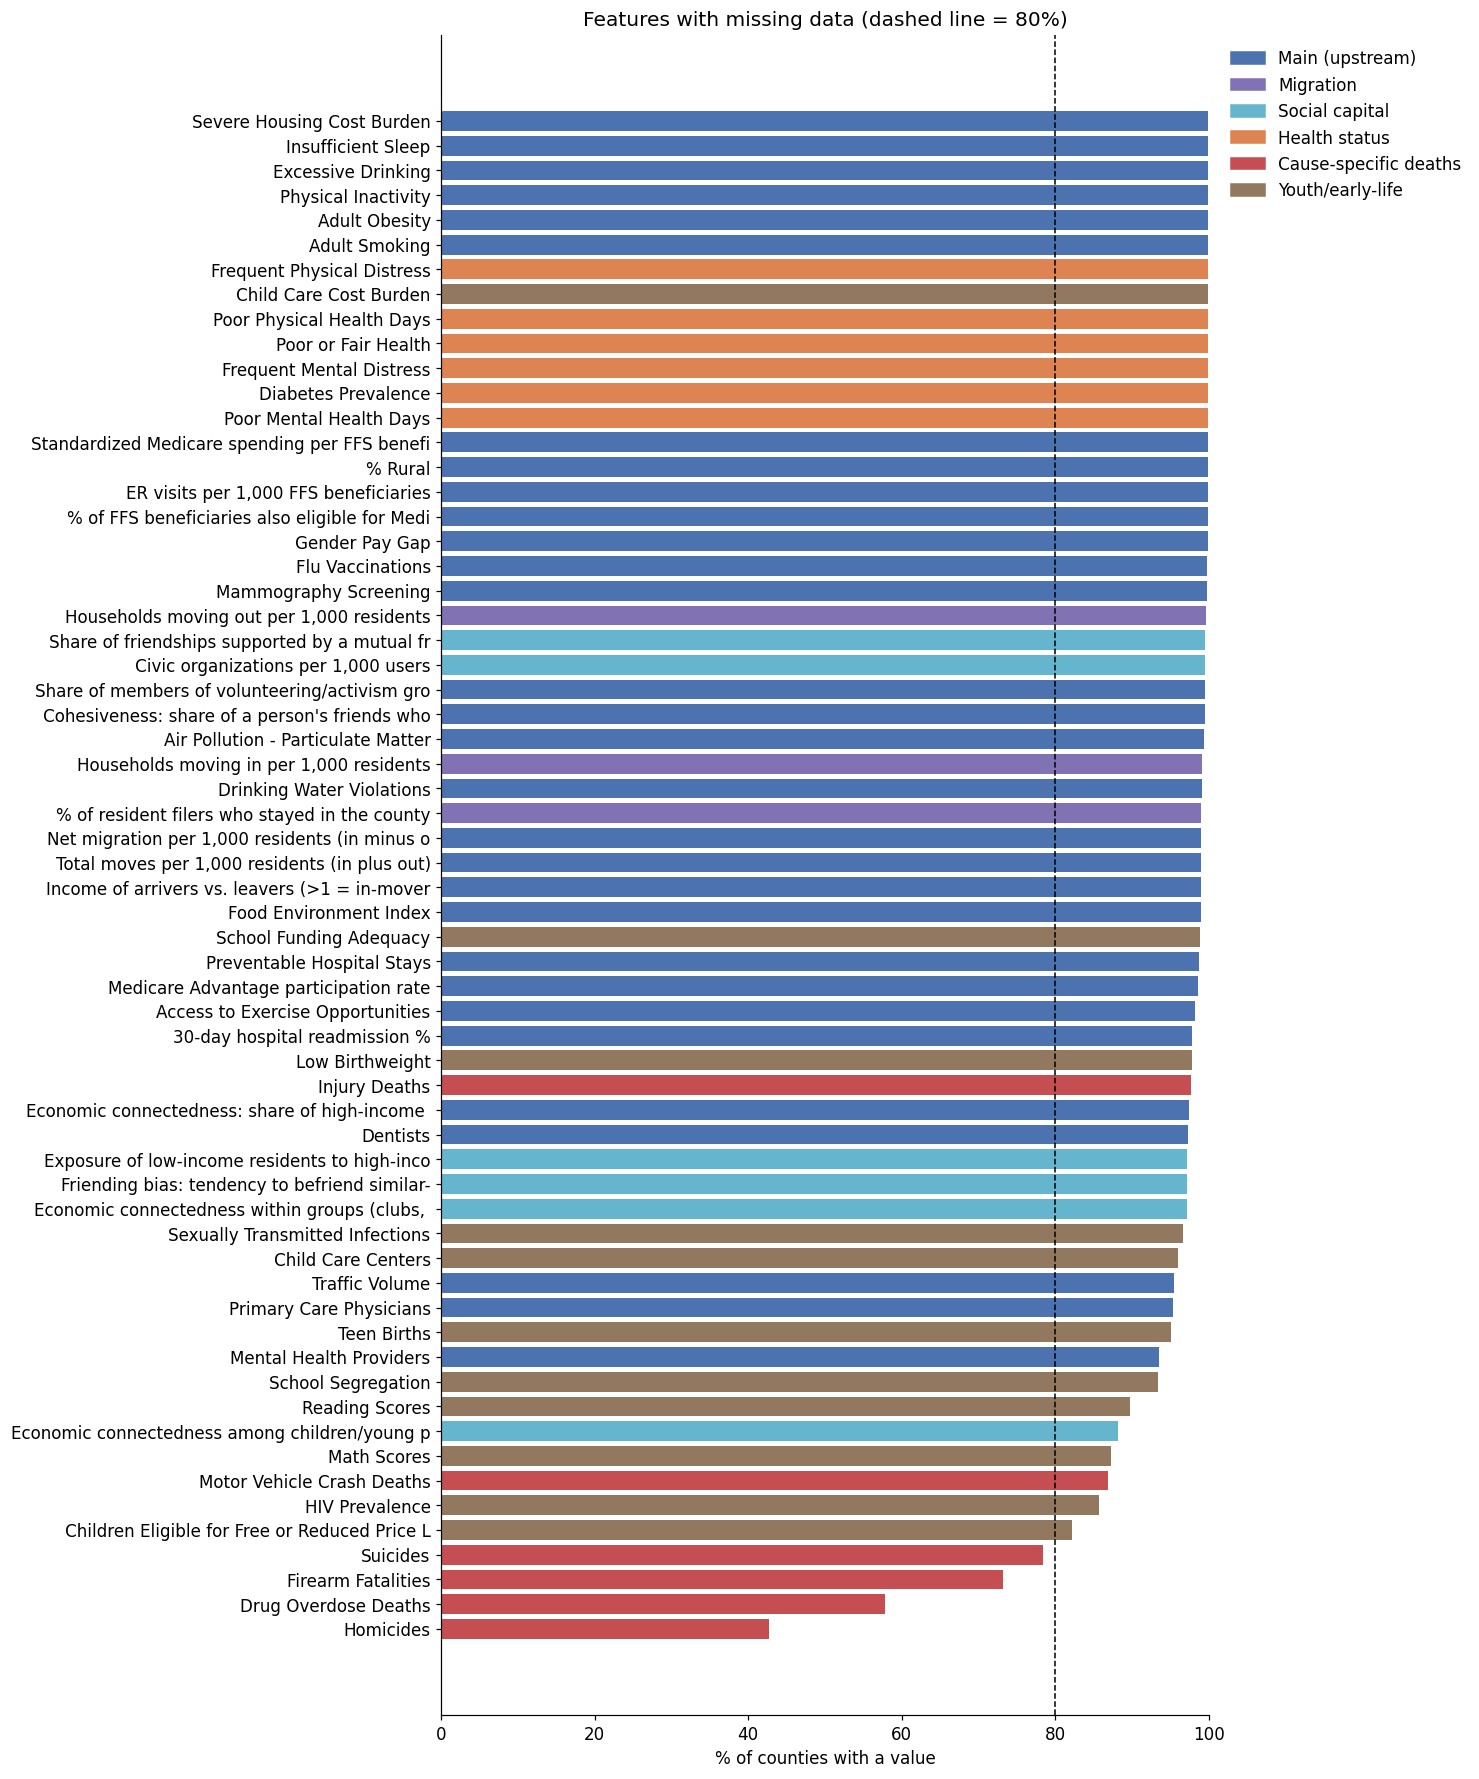

Who is missing? (if the two population columns differ a lot, missingness is systematic)


,feature,pct_filled,median pop (has data),median pop (missing),mean LE50 (has data),mean LE50 (missing)
0,Homicides,42.6,82853,13850,30.7,31.1
1,Drug Overdose Deaths,57.8,56765,9911,30.9,31.0
2,Firearm Fatalities,73.2,41697,6973,30.8,31.3
3,Suicides,78.4,38199,5991,30.9,31.2
4,Children Eligible for Free or Reduced Price L,82.2,25197,32001,30.9,30.9
5,HIV Prevalence,85.7,33478,7004,30.8,31.5
6,Motor Vehicle Crash Deaths,86.8,33173,4125,30.8,31.9
7,Math Scores,87.3,25560,31956,30.9,31.4
8,Economic connectedness among children/young p,88.2,32402,3946,30.9,31.1
9,Reading Scores,89.7,25773,32935,30.8,31.7


In [5]:
cov = (df[analysed].notna().mean() * 100).sort_values()
sparse = cov[cov < 100]

fig, ax = plt.subplots(figsize=(9, max(3, 0.32 * len(sparse))))
ax.barh([label(c) for c in sparse.index], sparse.values,
        color=[COLORS[group_of[c]] for c in sparse.index])
ax.axvline(80, color="black", ls="--", lw=1)
ax.set_xlim(0, 100)
ax.set_xlabel("% of counties with a value")
ax.set_title("Features with missing data (dashed line = 80%)")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[g])
           for g in COLORS if any(group_of.get(c) == g for c in sparse.index)]
labels_ = [g for g in COLORS if any(group_of.get(c) == g for c in sparse.index)]
ax.legend(handles, labels_, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
save(fig, "01_missingness")
plt.show()

rows = []
for c in cov[cov < 95].index:
    miss = df[c].isna()
    rows.append({
        "feature": label(c), "pct_filled": round(cov[c], 1),
        "median pop (has data)": int(pop[~miss].median()),
        "median pop (missing)": int(pop[miss].median()),
        "mean LE50 (has data)": round(df.loc[~miss, OUTCOME].mean(), 1),
        "mean LE50 (missing)": round(df.loc[miss, OUTCOME].mean(), 1),
    })
print("Who is missing? (if the two population columns differ a lot, missingness is systematic)")
pd.DataFrame(rows).sort_values("pct_filled")

## 6. The outcome

Saved C:\Users\14438\data\processed\figures\02_outcome_distribution.png


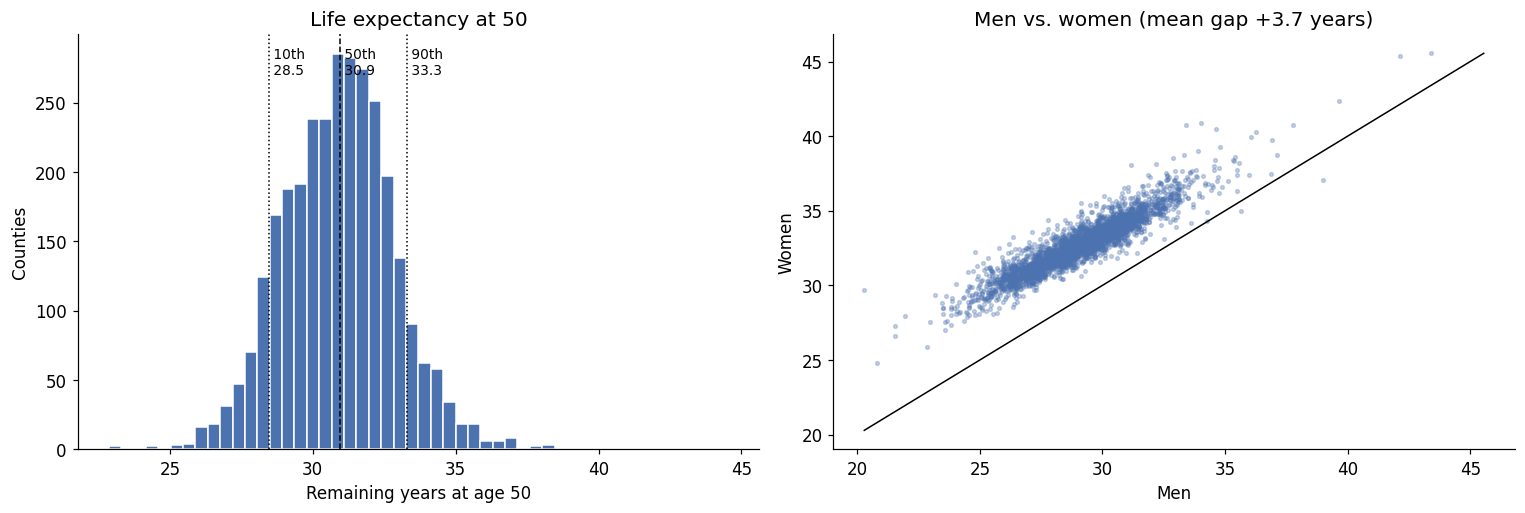

Highest 10:


,county_name,state,le50_both,le50_male,le50_female,acs_total_pop
286,Summit County,CO,44.5,43.4,45.6,30649.0
277,Pitkin County,CO,43.8,42.1,45.4,17926.0
250,Eagle County,CO,41.0,39.6,42.3,54681.0
284,San Miguel County,CO,39.2,37.8,40.7,8049.0
312,Collier County,FL,38.3,36.2,40.3,371453.0
67,Aleutians West CA,AK,38.3,39.0,37.0,9083.0
202,Mono County,CA,38.2,36.9,39.8,14310.0
2664,Presidio County,TX,37.9,36.1,40.0,6975.0
3075,Teton County,WY,37.9,37.1,38.7,23280.0
73,Haines Borough,AK,37.5,34.6,40.4,2518.0


Lowest 10:


,county_name,state,le50_both,le50_male,le50_female,acs_total_pop
2876,Martinsville city,VA,22.9,20.8,24.8,12852.0
364,Union County,FL,22.9,20.3,29.7,15303.0
2871,Galax city,VA,24.1,21.5,26.6,6517.0
1069,Perry County,KY,24.3,22.8,25.9,26624.0
2371,Shannon County,SD,24.4,21.5,27.3,14335.0
2880,Petersburg city,VA,25.1,22.0,27.9,31362.0
1020,Harlan County,KY,25.3,23.0,27.6,26699.0
1038,Leslie County,KY,25.3,23.6,27.0,10283.0
1071,Powell County,KY,25.5,23.6,27.6,12304.0
998,Clay County,KY,25.6,23.8,27.4,20368.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
ax.hist(df[OUTCOME], bins=50, color="#4C72B0", edgecolor="white")
for q, ls in [(0.1, ":"), (0.5, "--"), (0.9, ":")]:
    v = df[OUTCOME].quantile(q)
    ax.axvline(v, color="black", linestyle=ls, linewidth=1)
    ax.text(v, ax.get_ylim()[1] * 0.97, f" {int(q*100)}th\n {v:.1f}", fontsize=9, va="top")
ax.set_xlabel("Remaining years at age 50")
ax.set_ylabel("Counties")
ax.set_title("Life expectancy at 50")

ax = axes[1]
ax.scatter(df["le50_male"], df["le50_female"], s=6, alpha=0.3, color="#4C72B0")
lims = [min(df.le50_male.min(), df.le50_female.min()), max(df.le50_male.max(), df.le50_female.max())]
ax.plot(lims, lims, color="black", lw=1)
ax.set_xlabel("Men"); ax.set_ylabel("Women")
ax.set_title(f"Men vs. women (mean gap {(df.le50_female - df.le50_male).mean():+.1f} years)")
fig.tight_layout()
save(fig, "02_outcome_distribution")
plt.show()

cols = ["county_name", "state", OUTCOME, "le50_male", "le50_female", "acs_total_pop"]
print("Highest 10:"); display(df.nlargest(10, OUTCOME)[cols].round(1))
print("Lowest 10:");  display(df.nsmallest(10, OUTCOME)[cols].round(1))

### Does the female-male gap vary?
A wide gap often signals causes that hit men harder — injury, overdose, cardiovascular
disease — so the gap is worth a look of its own.

count    3078.00
mean        3.67
std         0.82
min        -1.95
25%         3.15
50%         3.63
75%         4.12
max         9.40
Saved C:\Users\14438\data\processed\figures\03_map_sex_gap.png


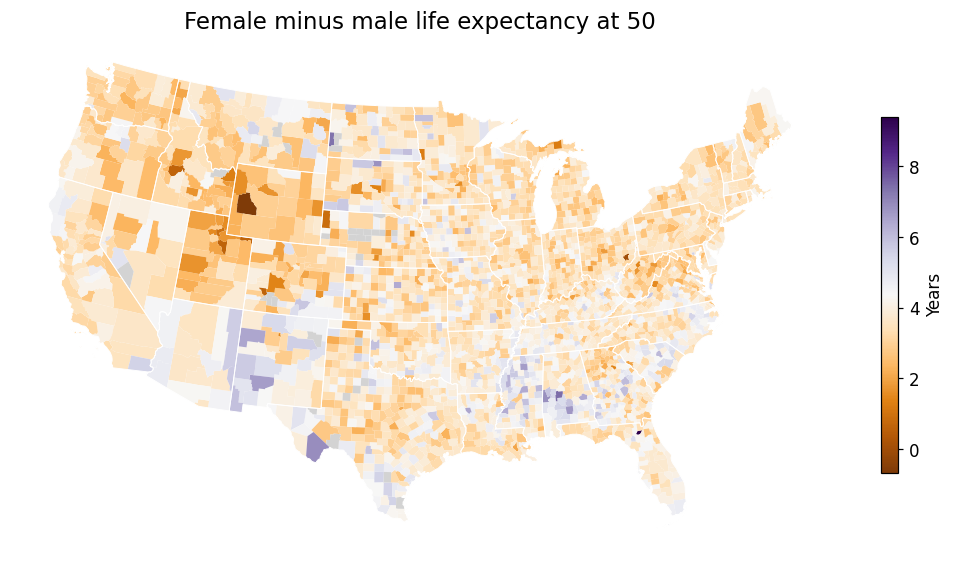

               county_name state  sex_gap  le50_both
364           Union County    FL      9.4       22.9
52            Perry County    AL      7.5       28.6
1966  Golden Valley County    ND      7.4       37.1
2502       Brewster County    TX      6.9       34.4
59           Sumter County    AL      6.9       29.9


In [7]:
df["sex_gap"] = df["le50_female"] - df["le50_male"]
print(df["sex_gap"].describe().round(2).to_string())
county_map(df, "sex_gap", "Female minus male life expectancy at 50",
           "03_map_sex_gap", cmap="PuOr", legend_label="Years")
print(df.nlargest(5, "sex_gap")[["county_name", "state", "sex_gap", OUTCOME]].round(1))

## 7. Geography

Saved C:\Users\14438\data\processed\figures\04_map_le50.png


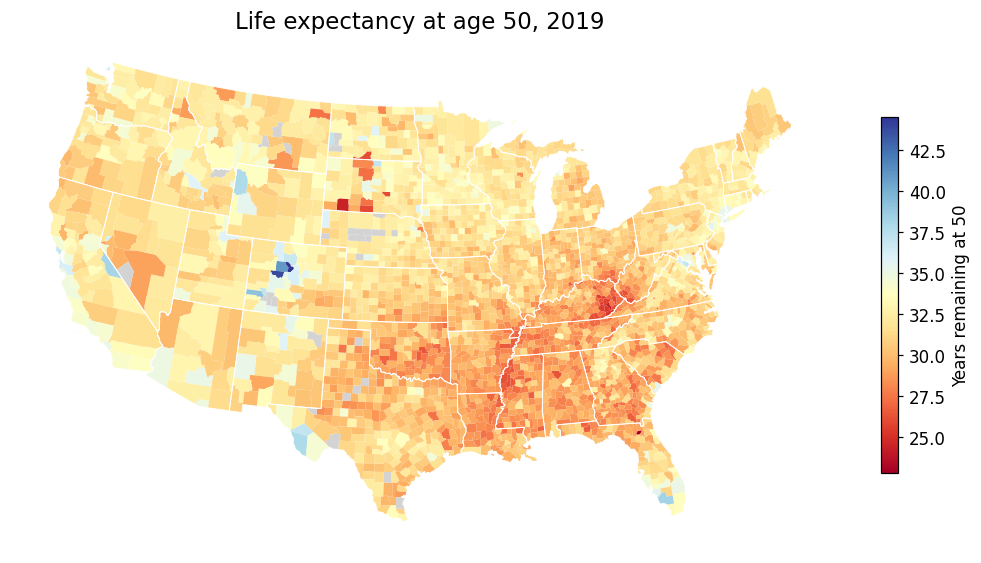

In [8]:
county_map(df, OUTCOME, "Life expectancy at age 50, 2019", "04_map_le50",
           cmap="RdYlBu", legend_label="Years remaining at 50")

Saved C:\Users\14438\data\processed\figures\05_rurality_region.png


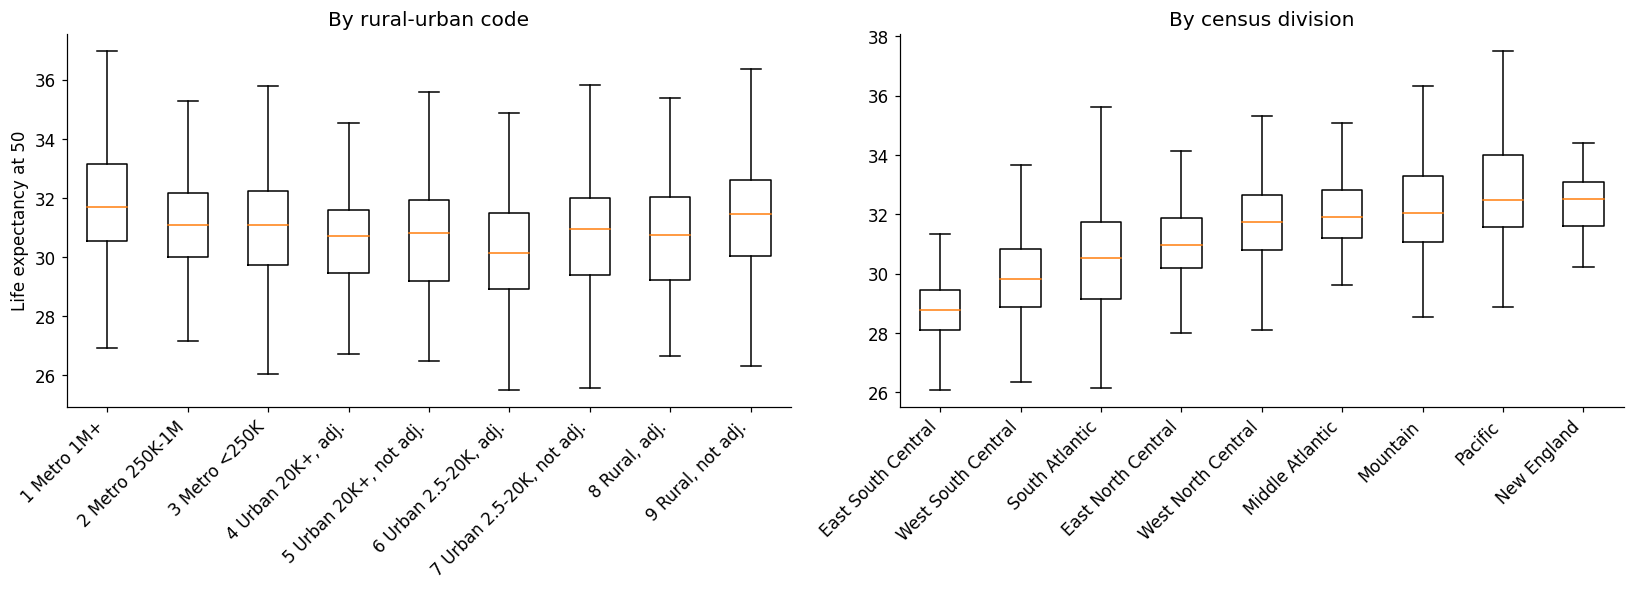

rucc      1.0     2.0     3.0     4.0    5.0     6.0     7.0     8.0     9.0
count  421.00  376.00  350.00  213.00  92.00  588.00  433.00  217.00  389.00
mean    31.76   31.12   31.06   30.64  30.91   30.16   30.75   30.71   31.35


In [9]:
RUCC_LABELS = {1: "1 Metro 1M+", 2: "2 Metro 250K-1M", 3: "3 Metro <250K",
               4: "4 Urban 20K+, adj.", 5: "5 Urban 20K+, not adj.",
               6: "6 Urban 2.5-20K, adj.", 7: "7 Urban 2.5-20K, not adj.",
               8: "8 Rural, adj.", 9: "9 Rural, not adj."}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].boxplot([df.loc[df["rucc"] == k, OUTCOME].dropna() for k in RUCC_LABELS], showfliers=False)
axes[0].set_xticks(range(1, 10), list(RUCC_LABELS.values()), rotation=45, ha="right")
axes[0].set_ylabel("Life expectancy at 50")
axes[0].set_title("By rural-urban code")

order = df.groupby("census_division")[OUTCOME].median().sort_values().index
axes[1].boxplot([df.loc[df["census_division"] == d, OUTCOME] for d in order], showfliers=False)
axes[1].set_xticks(range(1, len(order) + 1), order, rotation=45, ha="right")
axes[1].set_title("By census division")
fig.tight_layout()
save(fig, "05_rurality_region")
plt.show()

print(df.groupby("rucc")[OUTCOME].agg(["count", "mean"]).round(2).T)

### How much variation is geographic?
If most of the variation sits *between* states and regions, a model trained on some
regions may not transfer to others — which is the argument for spatial cross-validation
in the modeling phase.

In [10]:
def between_share(group_col):
    g = df.groupby(group_col)[OUTCOME]
    total = ((df[OUTCOME] - df[OUTCOME].mean()) ** 2).sum()
    within = ((df[OUTCOME] - g.transform("mean")) ** 2).sum()
    return 100 * (1 - within / total)

for col in ["state", "census_division", "rucc"]:
    print(f"{col:17} explains {between_share(col):5.1f}% of the variance in LE50")

# Spatial autocorrelation: compare each county with its 5 nearest neighbours
cent = lower48.drop_duplicates("fips").set_index("fips").geometry.centroid
sub = df[df["fips"].isin(cent.index)].copy()
xy = np.c_[cent.loc[sub["fips"]].x.values, cent.loc[sub["fips"]].y.values]
d2 = ((xy[:, None, :] - xy[None, :, :]) ** 2).sum(-1)
np.fill_diagonal(d2, np.inf)
nn = np.argsort(d2, axis=1)[:, :5]
neigh_mean = sub[OUTCOME].values[nn].mean(axis=1)
print(f"\nCorrelation with the average of the 5 nearest counties: "
      f"{np.corrcoef(sub[OUTCOME], neigh_mean)[0,1]:.2f}")
print("(high = neighbours look alike, so random train/test splits leak information)")

state             explains  42.4% of the variance in LE50
census_division   explains  33.1% of the variance in LE50
rucc              explains   6.3% of the variance in LE50

Correlation with the average of the 5 nearest counties: 0.76
(high = neighbours look alike, so random train/test splits leak information)


## 8. What correlates with the outcome?
Spearman (rank) correlations, so outliers and non-linear-but-monotonic relationships
are handled sensibly. These are associations, not causes.

Saved C:\Users\14438\data\processed\figures\06_top_correlations.png


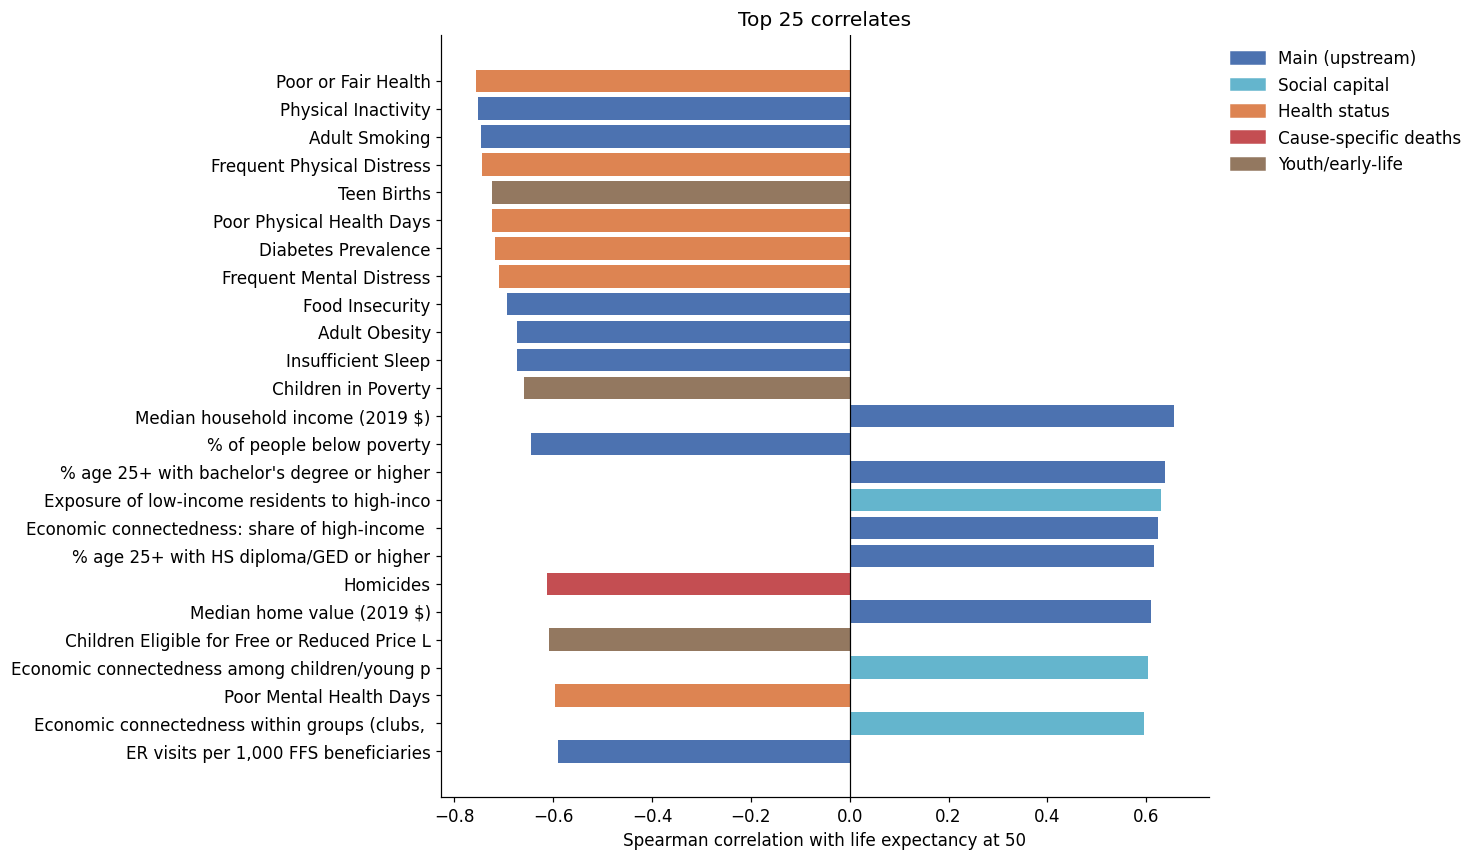

,spearman_r,group,label
chr_poor_or_fair_health,-0.756,Health status,Poor or Fair Health
chr_physical_inactivity,-0.753,Main (upstream),Physical Inactivity
chr_adult_smoking,-0.745,Main (upstream),Adult Smoking
chr_frequent_physical_distress,-0.744,Health status,Frequent Physical Distress
chr_teen_births,-0.724,Youth/early-life,Teen Births
chr_poor_physical_health_days,-0.723,Health status,Poor Physical Health Days
chr_diabetes_prevalence,-0.718,Health status,Diabetes Prevalence
chr_frequent_mental_distress,-0.709,Health status,Frequent Mental Distress
chr_food_insecurity,-0.693,Main (upstream),Food Insecurity
chr_adult_obesity,-0.674,Main (upstream),Adult Obesity


In [11]:
corr = (df[analysed].corrwith(df[OUTCOME], method="spearman")
        .dropna().sort_values(key=abs, ascending=False))
top = corr.head(25)[::-1]

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh([label(c) for c in top.index], top.values,
        color=[COLORS[group_of[c]] for c in top.index])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Spearman correlation with life expectancy at 50")
ax.set_title("Top 25 correlates")
present = [g for g in COLORS if any(group_of.get(c) == g for c in top.index)]
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[g]) for g in present], present,
          loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
save(fig, "06_top_correlations")
plt.show()

corr_table = corr.rename("spearman_r").to_frame()
corr_table["group"] = corr_table.index.map(group_of)
corr_table["label"] = corr_table.index.map(label)
corr_table.round(3).to_csv(DATA_DIR / "eda_correlations.csv")
corr_table.round(3).head(25)

### Strongest correlate in each group

In [12]:
rows = []
for g, cols in GROUPS.items():
    have = [c for c in cols if c in corr.index]
    if not have:
        continue
    s = corr[have]
    rows.append({"group": g, "n": len(have),
                 "strongest": label(s.abs().idxmax()),
                 "r": round(s[s.abs().idxmax()], 3),
                 "median |r| in group": round(s.abs().median(), 3)})
pd.DataFrame(rows).sort_values("median |r| in group", ascending=False)

,group,n,strongest,r,median |r| in group
3,Health status,6,Poor or Fair Health,-0.756,0.720
4,Cause-specific deaths,6,Homicides,-0.613,0.497
2,Social capital,9,Exposure of low-income residents to high-inco,0.629,0.429
0,Main (upstream),55,Physical Inactivity,-0.753,0.331
5,Youth/early-life,13,Teen Births,-0.724,0.321
1,Migration,6,"Total moves per 1,000 residents (in plus out)",0.327,0.210


## 9. Group close-ups
Each panel asks whether a group of features is worth carrying into the modeling phase.

Ranks are out of 89 features.
Saved C:\Users\14438\data\processed\figures\07a_migration.png


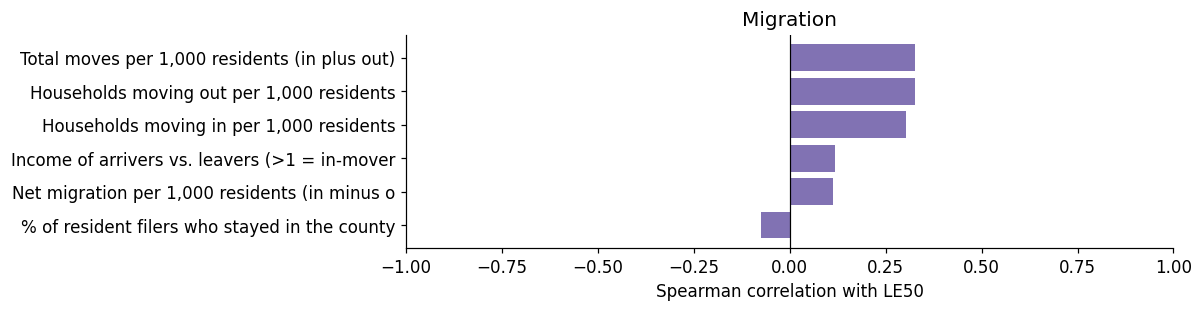

,r,rank of all,% filled
% of resident filers who stayed in the county,-0.076,81,99.0
"Net migration per 1,000 residents (in minus o",0.113,76,99.0
Income of arrivers vs. leavers (>1 = in-mover,0.117,75,99.0
"Households moving in per 1,000 residents",0.303,57,99.1
"Households moving out per 1,000 residents",0.326,51,99.6
"Total moves per 1,000 residents (in plus out)",0.327,50,99.0


Saved C:\Users\14438\data\processed\figures\07b_social_capital.png


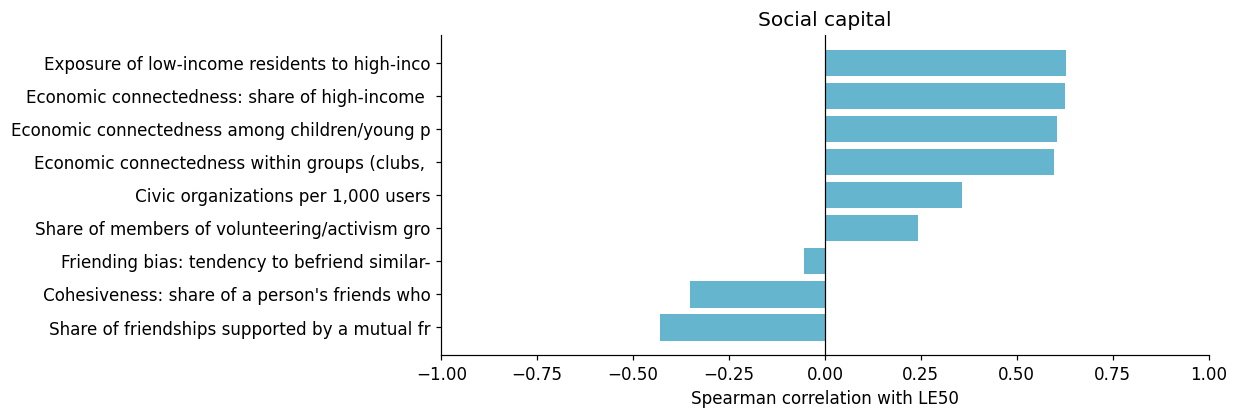

,r,rank of all,% filled
Share of friendships supported by a mutual fr,-0.429,39,99.5
Cohesiveness: share of a person's friends who,-0.351,43,99.5
Friending bias: tendency to befriend similar-,-0.054,84,97.2
Share of members of volunteering/activism gro,0.243,61,99.5
"Civic organizations per 1,000 users",0.357,42,99.5
"Economic connectedness within groups (clubs,",0.596,24,97.2
Economic connectedness among children/young p,0.604,22,88.2
Economic connectedness: share of high-income,0.624,17,97.4
Exposure of low-income residents to high-inco,0.629,16,97.2


In [13]:
def group_chart(name, fname):
    cols = [c for c in GROUPS[name] if c in corr.index]
    s = corr[cols].sort_values()
    fig, ax = plt.subplots(figsize=(9, max(2.5, 0.42 * len(s))))
    ax.barh([label(c) for c in s.index], s.values, color=COLORS[name])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-1, 1)
    ax.set_xlabel("Spearman correlation with LE50")
    ax.set_title(name)
    save(fig, fname)
    plt.show()
    return pd.DataFrame({
        "r": s.round(3),
        "rank of all": [list(corr.index).index(c) + 1 for c in s.index],
        "% filled": (df[s.index].notna().mean() * 100).round(1).values,
    }).set_index(pd.Index([label(c) for c in s.index]))

print(f"Ranks are out of {len(corr)} features.")
display(group_chart("Migration", "07a_migration"))
display(group_chart("Social capital", "07b_social_capital"))

Saved C:\Users\14438\data\processed\figures\07c_youth.png


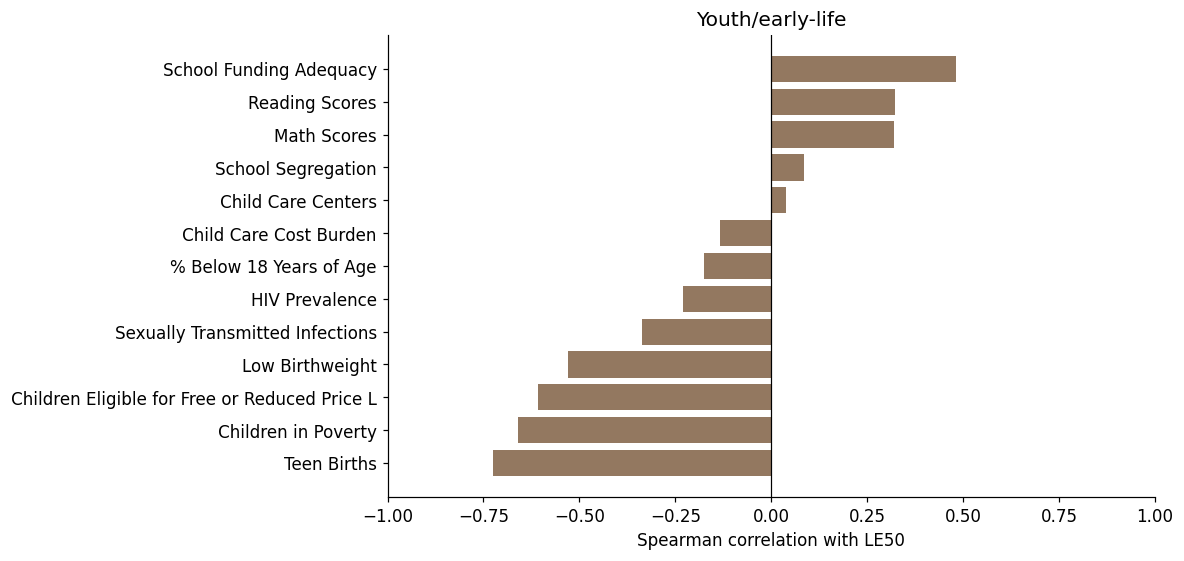

,r,rank of all,% filled
Teen Births,-0.724,5,95.2
Children in Poverty,-0.660,12,100.0
Children Eligible for Free or Reduced Price L,-0.608,21,82.2
Low Birthweight,-0.531,31,97.8
Sexually Transmitted Infections,-0.336,45,96.6
HIV Prevalence,-0.231,62,85.7
% Below 18 Years of Age,-0.174,69,100.0
Child Care Cost Burden,-0.135,73,100.0
Child Care Centers,0.038,87,96.0
School Segregation,0.086,80,93.4


Saved C:\Users\14438\data\processed\figures\07d_mortality.png


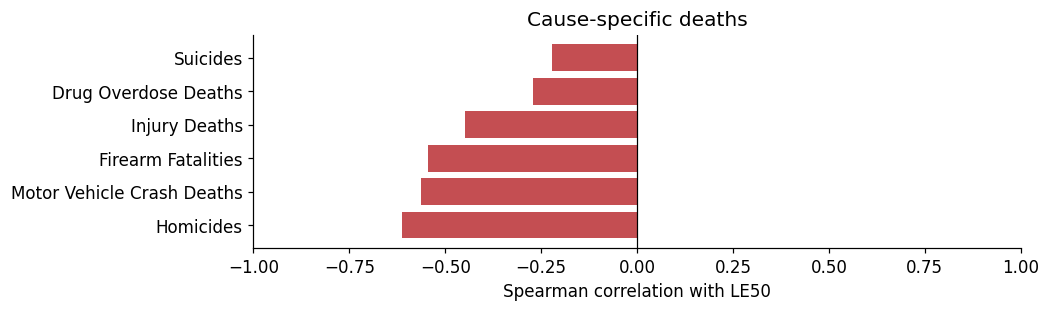

,r,rank of all,% filled
Homicides,-0.613,19,42.6
Motor Vehicle Crash Deaths,-0.564,27,86.8
Firearm Fatalities,-0.545,28,73.2
Injury Deaths,-0.448,38,97.8
Drug Overdose Deaths,-0.270,60,57.8
Suicides,-0.221,63,78.4


In [14]:
display(group_chart("Youth/early-life", "07c_youth"))
display(group_chart("Cause-specific deaths", "07d_mortality"))

These two groups need care in the modeling phase. Health-status measures describe how
sick a population already is, and cause-specific deaths are drawn from the same death
records as the outcome, so both will predict well for reasons that are not explanatory.

Saved C:\Users\14438\data\processed\figures\07e_health_status.png


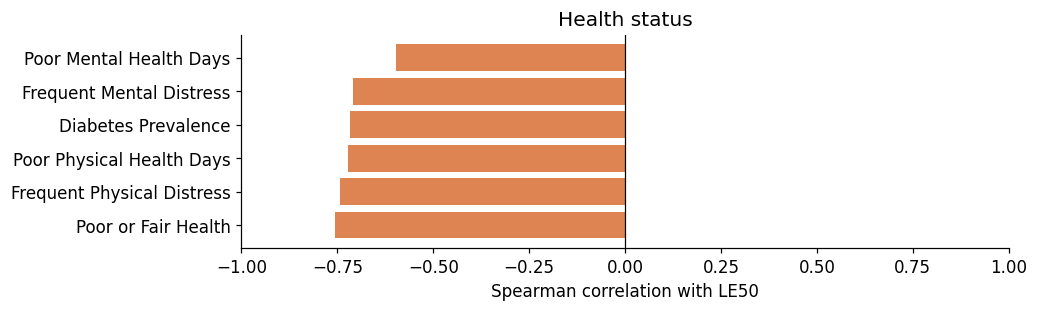

,r,rank of all,% filled
Poor or Fair Health,-0.756,1,100.0
Frequent Physical Distress,-0.744,4,100.0
Poor Physical Health Days,-0.723,6,100.0
Diabetes Prevalence,-0.718,7,100.0
Frequent Mental Distress,-0.709,8,100.0
Poor Mental Health Days,-0.596,23,100.0


Overlap with adult poverty (Spearman):
  Low Birthweight                               +0.55
  Teen Births                                   +0.66
  Children in Poverty                           +0.84
  % Below 18 Years of Age                       +0.00
  Child Care Cost Burden                        +0.36
  Child Care Centers                            +0.02
  School Funding Adequacy                       -0.58
  Reading Scores                                -0.44
  Math Scores                                   -0.45
  School Segregation                            +0.05
  Children Eligible for Free or Reduced Price L +0.74
  Sexually Transmitted Infections               +0.42
  HIV Prevalence                                +0.34


In [15]:
display(group_chart("Health status", "07e_health_status"))

# Are the child measures just proxies for adult poverty?
print("Overlap with adult poverty (Spearman):")
for c in GROUPS["Youth/early-life"]:
    if c in df:
        print(f"  {label(c):45} {df[c].corr(df['acs_pct_poverty'], method='spearman'):+.2f}")

## 10. Shape of the strongest relationships

Saved C:\Users\14438\data\processed\figures\08_scatter_top.png


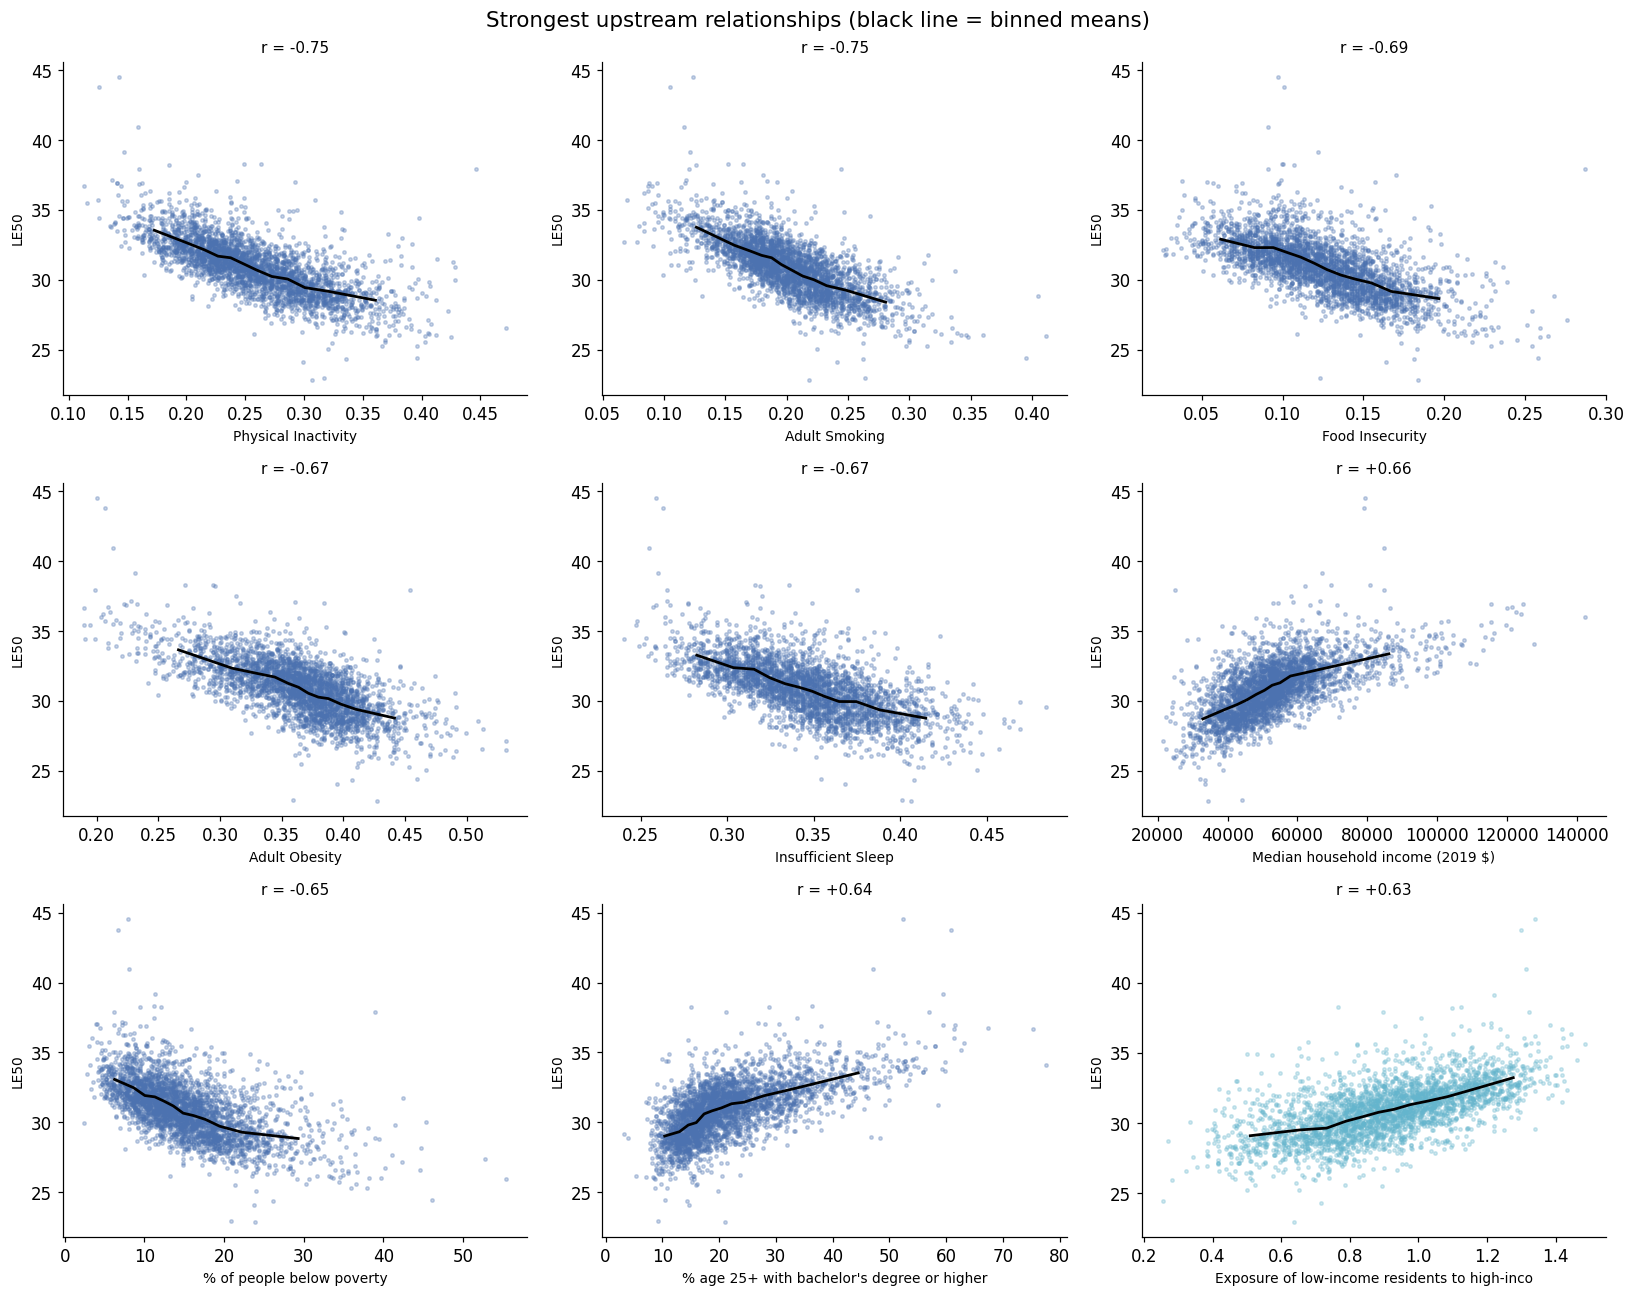

In [17]:
top_main = [c for c in corr.index if group_of[c] in ("Main (upstream)", "Migration",
                                                     "Social capital")][:9]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, c in zip(axes.flat, top_main):
    d = df[[c, OUTCOME]].dropna()
    ax.scatter(d[c], d[OUTCOME], s=5, alpha=0.3, color=COLORS[group_of[c]])
    # smooth trend: mean outcome within 12 bins of the predictor
    q = pd.qcut(d[c], 12, duplicates="drop")
    tr = d.groupby(q, observed=True).agg({c: "mean", OUTCOME: "mean"})
    ax.plot(tr[c], tr[OUTCOME], color="black", lw=1.8)
    ax.set_xlabel(label(c), fontsize=9)
    ax.set_ylabel("LE50", fontsize=9)
    ax.set_title(f"r = {corr[c]:+.2f}", fontsize=10)
fig.suptitle("Strongest upstream relationships (black line = binned means)", fontsize=14)
fig.tight_layout()
save(fig, "08_scatter_top")
plt.show()

A curved black line means the relationship is non-linear, which is an argument for tree
models over plain linear regression — worth noting now rather than discovering later.

## 11. Distributions and skew
Heavily skewed features distort linear models. This flags the ones a log transform would
help, which is a decision for the modeling phase.

17 of 55 main features are heavily skewed (|skew| > 1.5):
Traffic Volume                                   8.32
% non-Hispanic American Indian/Alaska Native     8.15
% non-Hispanic Asian                             6.91
Dentists                                         5.32
% Not Proficient in English                      4.44
Mental Health Providers                          4.19
Median home value (2019 $)                       3.65
% Hispanic or Latino                             3.09
% Female                                        -3.09
% foreign born                                   2.89
Primary Care Physicians                          2.61
Severe Housing Problems                          2.60
% non-Hispanic Black                             2.30
Income of arrivers vs. leavers (>1 = in-mover    2.05
Net migration per 1,000 residents (in minus o   -1.83
% of civilian labor force unemployed             1.65
Total moves per 1,000 residents (in plus out)    1.56
Saved C:\Users\14438\dat

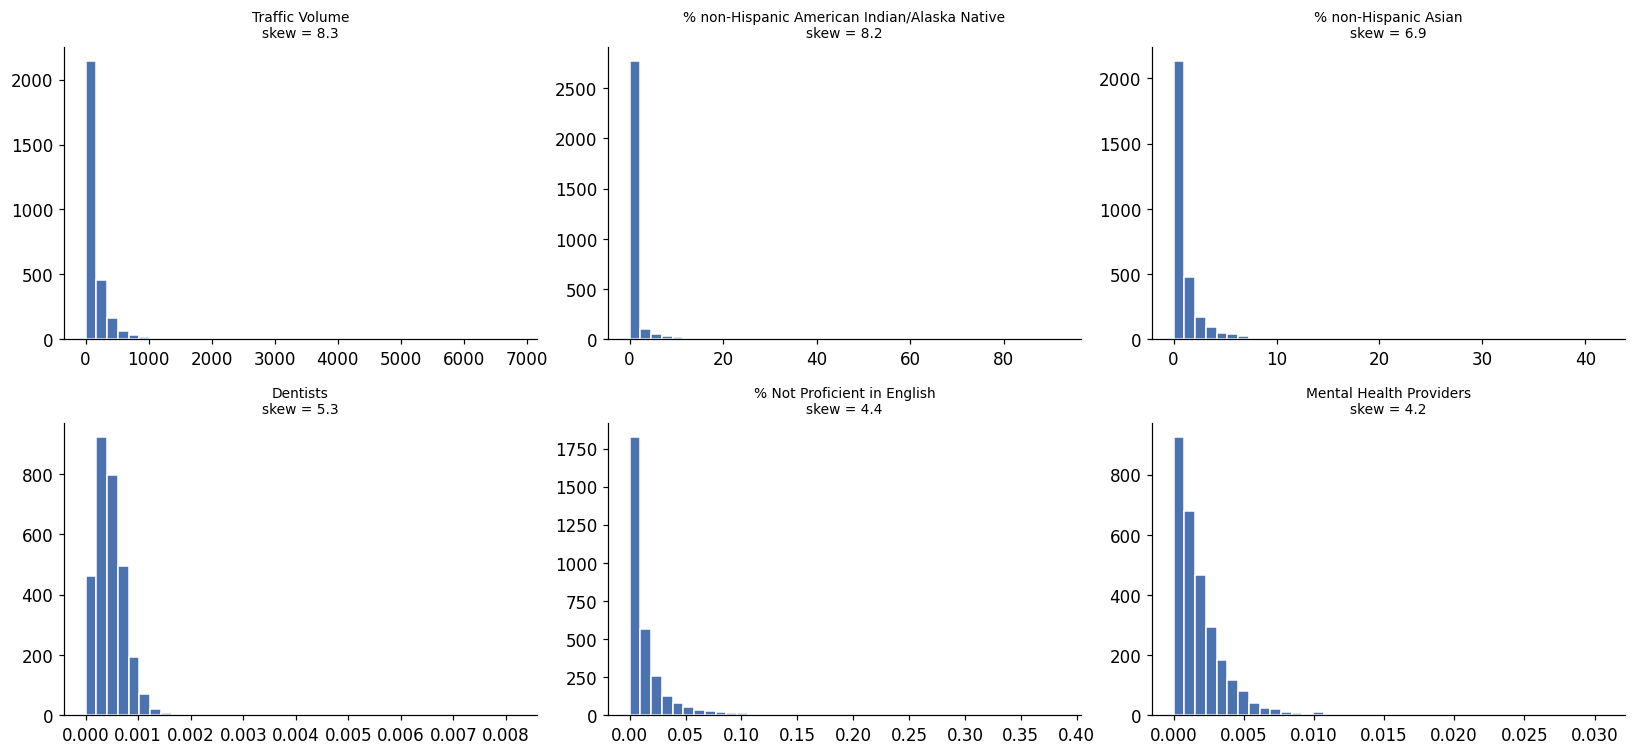

In [18]:
skew = df[features_main].skew().sort_values(key=abs, ascending=False)
heavy = skew[skew.abs() > 1.5]
print(f"{len(heavy)} of {len(features_main)} main features are heavily skewed (|skew| > 1.5):")
print(heavy.round(2).rename(index=label).to_string())

if len(heavy):
    show = heavy.index[:6]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, c in zip(axes.flat, show):
        ax.hist(df[c].dropna(), bins=40, color="#4C72B0", edgecolor="white")
        ax.set_title(f"{label(c)}\nskew = {skew[c]:.1f}", fontsize=9)
    for ax in axes.flat[len(show):]:
        ax.set_visible(False)
    fig.tight_layout()
    save(fig, "09_skewed_features")
    plt.show()

## 12. Overlap between predictors
Correlated features make coefficients unstable and split credit in importance scores.
VIF above about 10 means a feature is nearly a combination of the others.

Saved C:\Users\14438\data\processed\figures\10_correlation_heatmap.png


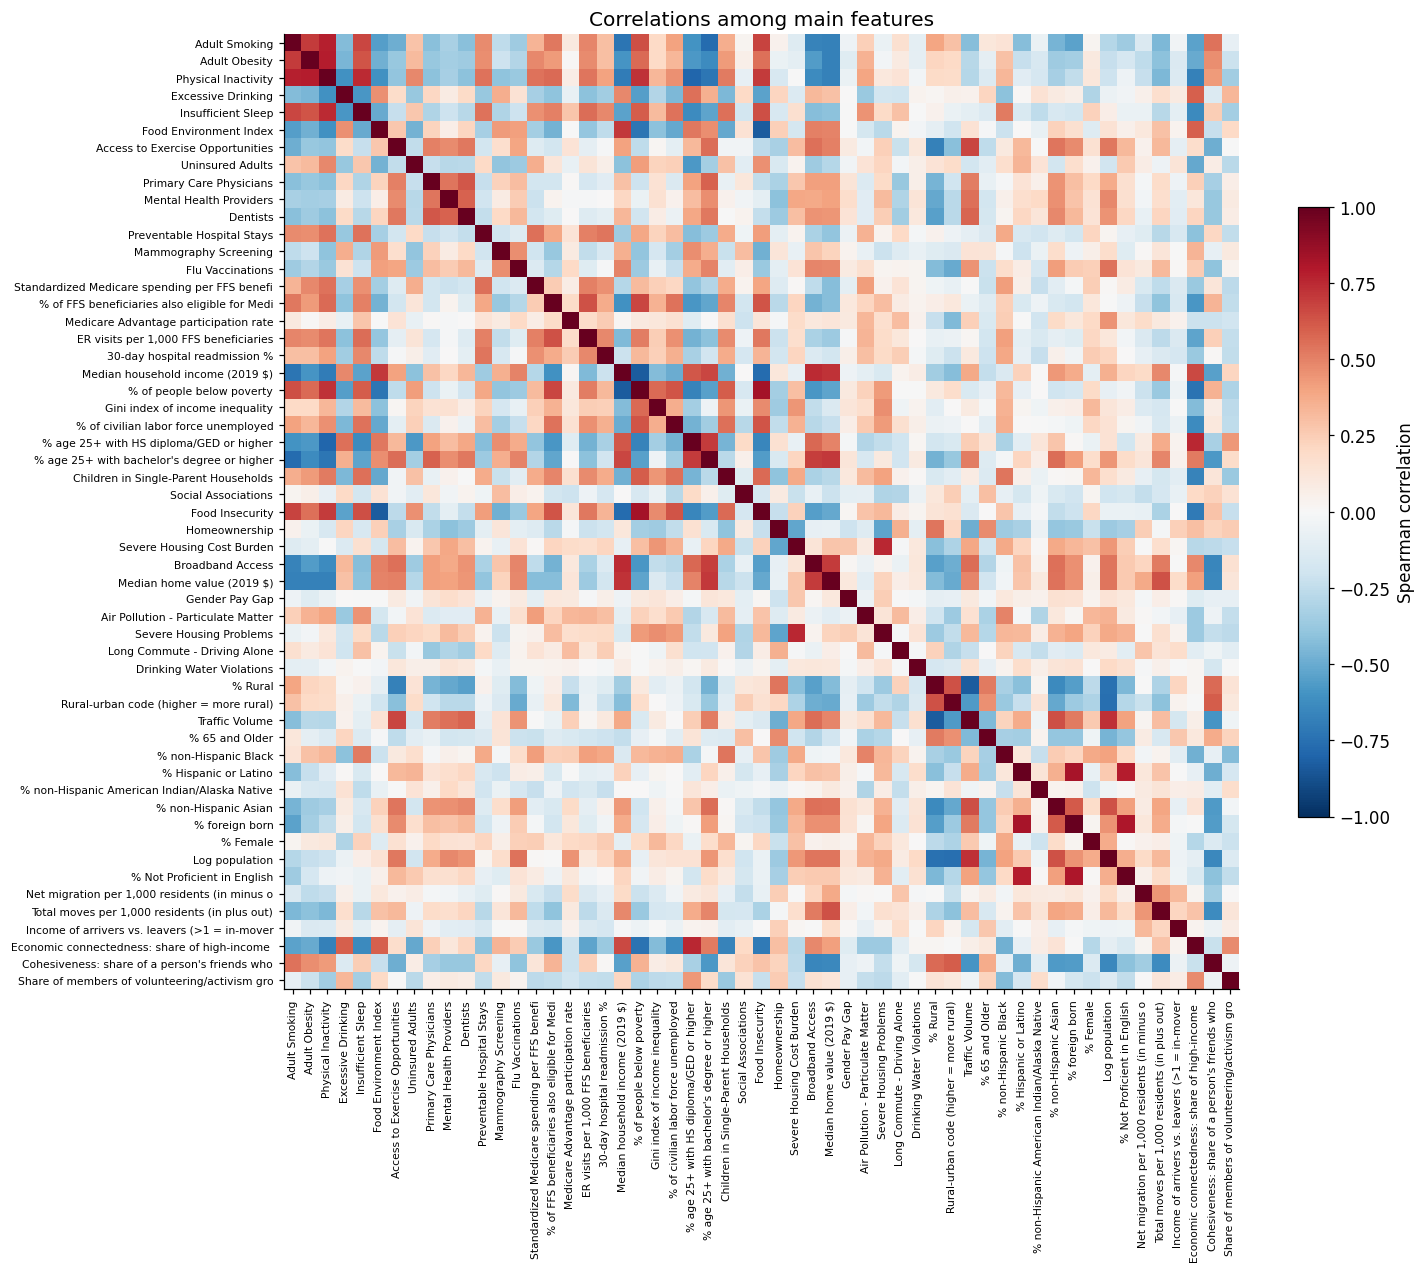

6 pairs with |r| > 0.8 (candidates to drop one of):
  -0.83  % Rural  <->  Traffic Volume
  -0.83  Median household income (2019 $)  <->  % of people below poverty
  +0.83  % of people below poverty  <->  Food Insecurity
  -0.83  Food Environment Index  <->  Food Insecurity
  +0.82  % Hispanic or Latino  <->  % foreign born
  +0.81  % foreign born  <->  % Not Proficient in English


In [19]:
cm = df[features_main].corr(method="spearman")

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cm)), [label(c) for c in cm.columns], rotation=90, fontsize=7)
ax.set_yticks(range(len(cm)), [label(c) for c in cm.index], fontsize=7)
fig.colorbar(im, shrink=0.6, label="Spearman correlation")
ax.set_title("Correlations among main features")
save(fig, "10_correlation_heatmap")
plt.show()

pairs = cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1)).stack()
high = pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False)
print(f"{len(high)} pairs with |r| > 0.8 (candidates to drop one of):")
for (a, b), v in high.items():
    print(f"  {v:+.2f}  {label(a)}  <->  {label(b)}")

In [20]:
# VIF: regress each feature on all the others (median-imputed, standardised)
X = df[features_main].apply(lambda s: s.fillna(s.median()))
X = (X - X.mean()) / X.std(ddof=0)
X = X.loc[:, X.std(ddof=0) > 0]
A = np.c_[np.ones(len(X)), X.values]
vifs = {}
for i, c in enumerate(X.columns):
    others = np.delete(A, i + 1, axis=1)
    beta, *_ = np.linalg.lstsq(others, X[c].values, rcond=None)
    resid = X[c].values - others @ beta
    r2 = 1 - resid.var() / X[c].values.var()
    vifs[c] = 1 / max(1 - r2, 1e-9)
vif = pd.Series(vifs).sort_values(ascending=False)
print("Highest VIFs (>10 = heavily overlapping):")
print(vif.head(12).round(1).rename(index=label).to_string())

Highest VIFs (>10 = heavily overlapping):
Adult Smoking                                 12.9
% foreign born                                12.6
Physical Inactivity                           11.8
Median household income (2019 $)              11.1
% of people below poverty                      8.7
% Not Proficient in English                    8.4
Food Insecurity                                7.7
Log population                                 7.5
% age 25+ with bachelor's degree or higher     7.2
% age 25+ with HS diploma/GED or higher        6.8
% Hispanic or Latino                           6.1
Median home value (2019 $)                     6.0


## 13. Outliers
Counties with extreme values are usually real and worth understanding — resort towns,
prison counties, university towns, reservations — rather than errors to delete.

Counties more than 3 SD from the mean outcome:


,county_name,state,le50_both,acs_total_pop,rucc
2876,Martinsville city,VA,22.9,12852.0,4.0
364,Union County,FL,22.9,15303.0,6.0
2871,Galax city,VA,24.1,6517.0,7.0
1069,Perry County,KY,24.3,26624.0,7.0
2371,Shannon County,SD,24.4,14335.0,6.0
256,Grand County,CO,36.9,15303.0,7.0
2917,San Juan County,WA,36.9,16788.0,9.0
197,Marin County,CA,36.9,259943.0,1.0
2799,Fairfax County,VA,37.0,1169393.0,1.0
2602,Jeff Davis County,TX,37.0,2241.0,9.0



Smallest counties (least reliable estimates):


,county_name,state,le50_both,acs_total_pop,rucc
2732,Daggett County,UT,32.9,613.0,9.0
2357,Jones County,SD,34.2,793.0,9.0
70,Bristol Bay Borough,AK,33.1,875.0,9.0
1593,Garfield County,MT,32.3,1036.0,9.0
178,Alpine County,CA,32.1,1039.0,8.0


Saved C:\Users\14438\data\processed\figures\11_population_vs_outcome.png


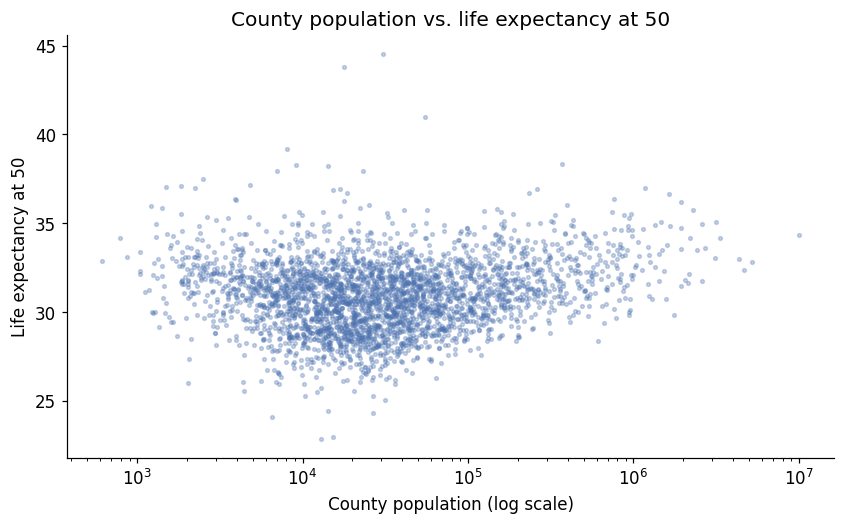

In [21]:
z = ((df[OUTCOME] - df[OUTCOME].mean()) / df[OUTCOME].std()).abs()
cols = ["county_name", "state", OUTCOME, "acs_total_pop", "rucc"]
print("Counties more than 3 SD from the mean outcome:")
display(df.loc[z > 3, cols].sort_values(OUTCOME).round(1))

print("\nSmallest counties (least reliable estimates):")
display(df.nsmallest(5, "acs_total_pop")[cols].round(1))

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df["acs_total_pop"], df[OUTCOME], s=6, alpha=0.3, color="#4C72B0")
ax.set_xscale("log")
ax.set_xlabel("County population (log scale)")
ax.set_ylabel("Life expectancy at 50")
ax.set_title("County population vs. life expectancy at 50")
save(fig, "11_population_vs_outcome")
plt.show()

## 14. Feature notes for the modeling phase
One row per feature: group, coverage, correlation, skew, and VIF. This file is the input
to feature selection in the next phase.

In [22]:
notes = pd.DataFrame({
    "feature": analysed,
    "label": [label(c) for c in analysed],
    "group": [group_of[c] for c in analysed],
    "pct_filled": (df[analysed].notna().mean() * 100).round(1).values,
    "spearman_r": [round(corr.get(c, np.nan), 3) for c in analysed],
    "skew": df[analysed].skew().round(2).values,
    "vif": [round(vif.get(c, np.nan), 1) for c in analysed],
})
notes["in_main_model"] = notes["feature"].isin(features_main)
notes["flag"] = np.select(
    [notes["pct_filled"] < 80, notes["vif"] > 10, notes["skew"].abs() > 1.5],
    ["low coverage", "high VIF - consider dropping", "skewed - consider log"],
    default="",
)
notes["_abs_r"] = notes["spearman_r"].abs()
notes = notes.sort_values(["group", "_abs_r"], ascending=[True, False]).drop(columns="_abs_r")
notes.to_csv(DATA_DIR / "eda_feature_notes.csv", index=False)
print(f"Saved {DATA_DIR / 'eda_feature_notes.csv'}")
print(notes["flag"].replace("", "ok").value_counts().to_string())
notes

Saved C:\Users\14438\data\processed\eda_feature_notes.csv
flag
ok                              57
skewed - consider log           24
low coverage                     4
high VIF - consider dropping     4


,feature,label,group,pct_filled,spearman_r,skew,vif,in_main_model,flag
75,chr_homicides,Homicides,Cause-specific deaths,42.6,-0.613,2.51,NaN,False,low coverage
71,chr_motor_vehicle_crash_deaths,Motor Vehicle Crash Deaths,Cause-specific deaths,86.8,-0.564,1.32,NaN,False,
73,chr_firearm_fatalities,Firearm Fatalities,Cause-specific deaths,73.2,-0.545,1.30,NaN,False,low coverage
70,chr_injury_deaths,Injury Deaths,Cause-specific deaths,97.8,-0.448,1.18,NaN,False,
74,chr_drug_overdose_deaths,Drug Overdose Deaths,Cause-specific deaths,57.8,-0.270,1.85,NaN,False,low coverage
...,...,...,...,...,...,...,...,...,...
88,chr_hiv_prevalence,HIV Prevalence,Youth/early-life,85.7,-0.231,3.56,NaN,False,skewed - consider log
79,chr_pct_below_18_years_of_age,% Below 18 Years of Age,Youth/early-life,100.0,-0.174,0.41,NaN,False,
80,chr_child_care_cost_burden,Child Care Cost Burden,Youth/early-life,100.0,-0.135,1.04,NaN,False,
85,chr_school_segregation,School Segregation,Youth/early-life,93.4,0.086,2.19,NaN,False,skewed - consider log


## 15. Summary for the slides

In [23]:
print(f"- {len(df):,} county units, {len(analysed)} features in {len(GROUPS)} groups")
print(f"- LE50 ranges {df[OUTCOME].min():.1f}-{df[OUTCOME].max():.1f} years; "
      f"10th-90th percentile gap is {df[OUTCOME].quantile(.9)-df[OUTCOME].quantile(.1):.1f} years")
print(f"- Women outlive men by {(df.le50_female-df.le50_male).mean():.1f} years at 50")
print(f"- State explains {between_share('state'):.0f}% of the variance -> use spatial cross-validation")
print(f"- Strongest correlate: {label(corr.index[0])} (r = {corr.iloc[0]:+.2f})")
for g in GROUPS:
    have = [c for c in GROUPS[g] if c in corr.index]
    if have:
        s = corr[have]
        print(f"- {g}: strongest is {label(s.abs().idxmax())} (r = {s[s.abs().idxmax()]:+.2f})")
print(f"- {(notes['flag'] != '').sum()} features flagged for coverage, collinearity or skew")
print(f"\nFigures: {FIG_DIR}")

- 3,079 county units, 89 features in 6 groups
- LE50 ranges 22.9-44.5 years; 10th-90th percentile gap is 4.8 years
- Women outlive men by 3.7 years at 50
- State explains 42% of the variance -> use spatial cross-validation
- Strongest correlate: Poor or Fair Health (r = -0.76)
- Main (upstream): strongest is Physical Inactivity (r = -0.75)
- Migration: strongest is Total moves per 1,000 residents (in plus out) (r = +0.33)
- Social capital: strongest is Exposure of low-income residents to high-inco (r = +0.63)
- Health status: strongest is Poor or Fair Health (r = -0.76)
- Cause-specific deaths: strongest is Homicides (r = -0.61)
- Youth/early-life: strongest is Teen Births (r = -0.72)
- 32 features flagged for coverage, collinearity or skew

Figures: C:\Users\14438\data\processed\figures
